# S3 Connection

In [2]:
%pip install boto3

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
!{sys.executable} -m pip install boto3

Defaulting to user installation because normal site-packages is not writeable


In [5]:
session = boto3.Session(
    aws_access_key_id="...",
    aws_secret_access_key="...",
    region_name="eu-central-1",
)

In [6]:
import boto3

# create an AWS session 
session = boto3.Session()

s3 = session.client("s3")

bucket_name = "dataset-mlops"

response = s3.list_objects_v2(
    Bucket=bucket_name,
    MaxKeys = 10
)

print("aws region", session.region_name)
print("s3 bucket", bucket_name)

print("files in S3: ")

for obj in response.get("Contents", []):
    print(obj["Key"])

NoCredentialsError: Unable to locate credentials

# Read Our First Dataset

In [8]:
import pandas as pd

# house_prices_key = "dataset/house prices/house_prices.csv"

# # read dataset from s3 (csv)
# house_prices = s3.get_object(  
#     Bucket=bucket_name,
#     Key=house_prices_key
# )

# # convert CSV to dataframe 
# df = pd.read_csv(house_prices["Body"])


# print("Dataset Shape:", df.shape)
# print("\nColumns:")
# print(df.columns.tolist())

# display(df.head())

In [11]:
# Inspect column data types and the number and percentage of missing values.

quality_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
}).sort_values("missing_count", ascending=False)

display(quality_report)

,dtype,missing_count,missing_pct
ID,int64,0,0.0
Date,object,0,0.0
Price,float64,0,0.0
Bedrooms,int64,0,0.0
Bathrooms,float64,0,0.0
Sqft_living,int64,0,0.0
Sqft_lot,int64,0,0.0
Floors,float64,0,0.0
Waterfront,int64,0,0.0
View,int64,0,0.0


In [12]:
# Drop `Plot Area` and `Dimensions` 

houses = df.drop(columns=["Plot Area", "Dimensions"]).copy()

print("Original shape:", df.shape)
print("Working shape:", houses.shape)


KeyError: "['Plot Area', 'Dimensions'] not found in axis"

In [17]:
# Exclude the Index column
columns = houses.columns.drop("Index")

# Count duplicate rows
duplicates = houses.duplicated(subset=columns)

print("Duplicate rows:", duplicates.sum())

KeyError: "['Index'] not found in axis"

In [15]:
# Find all copies of row 3
record = houses.loc[3, columns]

matches = (
    houses[columns].fillna("MISSING")
    .eq(record.fillna("MISSING"))
    .all(axis=1)
)

# Display matching records
houses.loc[matches, [
    "Index",
    "Title",
    "Amount(in rupees)",
    "location",
    "Carpet Area",
    "Super Area"
]]

NameError: name 'columns' is not defined

In [16]:
# Preview the dataset without exact duplicates
unique_houses = houses.drop_duplicates(subset=columns)

# Compare row counts
print("Before:", len(houses))
print("After:", len(unique_houses))
print("Removed:", len(houses) - len(unique_houses))

NameError: name 'columns' is not defined

In [9]:
# Keep the deduplicated dataset
houses = unique_houses.copy()

# Verify duplicate removal
print("Rows:", len(houses))
print("Duplicates:", houses.duplicated(subset=columns).sum())

Rows: 68192
Duplicates: 0


In [10]:
houses.info()

<class 'pandas.core.frame.DataFrame'>
Index: 68192 entries, 0 to 187530
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Index              68192 non-null  int64  
 1   Title              68192 non-null  object 
 2   Description        65974 non-null  object 
 3   Amount(in rupees)  68192 non-null  object 
 4   Price (in rupees)  62298 non-null  float64
 5   location           68192 non-null  object 
 6   Carpet Area        38075 non-null  object 
 7   Status             67893 non-null  object 
 8   Floor              65577 non-null  object 
 9   Transaction        68114 non-null  object 
 10  Furnishing         66902 non-null  object 
 11  facing             41392 non-null  object 
 12  overlooking        38657 non-null  object 
 13  Society            29372 non-null  object 
 14  Bathroom           67721 non-null  object 
 15  Balcony            49133 non-null  object 
 16  Car Parking        28863 n

In [11]:
# Remove `Price (in rupees)` from the working dataset to avoid potential data leakage.

houses = houses.drop(columns=["Price (in rupees)"])

print(houses.shape)

(68192, 18)


In [12]:
# Amount(in rupees)
# Check the most common property prices
print(houses["Amount(in rupees)"].value_counts().head(15))

# Inspect random price values
print(houses["Amount(in rupees)"].sample(10, random_state=42))

Amount(in rupees)
Call for Price    2937
45 Lac            1692
65 Lac            1628
55 Lac            1533
60 Lac            1425
40 Lac            1361
75 Lac            1333
35 Lac            1313
50 Lac            1297
70 Lac            1194
30 Lac            1048
85 Lac            1027
80 Lac             939
25 Lac             808
90 Lac             806
Name: count, dtype: int64
92399       75 Lac 
180987     1.50 Cr 
170438    25.9 Lac 
17364      1.22 Cr 
172872      33 Lac 
175078      30 Lac 
50970      1.30 Cr 
1933       6.15 Cr 
167461      75 Lac 
183852      52 Lac 
Name: Amount(in rupees), dtype: object


In [13]:
# Remove extra spaces
amount = houses["Amount(in rupees)"].str.strip()

# Count price formats
print(amount.str.split().str[-1].value_counts())

Amount(in rupees)
Lac      47232
Cr       18023
Price     2937
Name: count, dtype: int64


In [14]:
# Define conversion factors
price_factors = {
    "Lac": 100000,
    "Cr": 10000000
}

# Split price into value and unit
houses[["Amount_Value", "Amount_Unit"]] = (
    houses["Amount(in rupees)"].str.strip().str.split(
        n=1, expand=True
    )
)

# Convert values to numbers
houses["Amount_Value"] = pd.to_numeric(
    houses["Amount_Value"], errors="coerce"
)


# Convert prices to INR
houses["Amount_clean"] = (
    houses["Amount_Value"] *
    houses["Amount_Unit"].map(price_factors)
)

# Inspect results
houses[[
    "Amount(in rupees)",
    "Amount_clean"
]].head(10)

,Amount(in rupees),Amount_clean
0,42 Lac,4200000.0
1,98 Lac,9800000.0
2,1.40 Cr,14000000.0
3,25 Lac,2500000.0
4,1.60 Cr,16000000.0
5,45 Lac,4500000.0
6,16.5 Lac,1650000.0
7,60 Lac,6000000.0
8,60 Lac,6000000.0
9,1.60 Cr,16000000.0


In [15]:
# Count successfully converted prices
print("Converted:", houses["Amount_clean"].count())

# Count missing prices
print("Missing:", houses["Amount_clean"].isna().sum())

# Check price statistics
print(houses["Amount_clean"].describe())

Converted: 65255
Missing: 2937
count    6.525500e+04
mean     1.067909e+07
std      6.292519e+07
min      1.000000e+05
25%      4.100000e+06
50%      6.500000e+06
75%      1.090000e+07
max      1.400300e+10
Name: Amount_clean, dtype: float64


In [16]:
# Carpet Area & Super Area
# View sample values
print(houses[["Carpet Area", "Super Area"]].head(10))

# Check missing values in each area column
print(houses[["Carpet Area", "Super Area"]].isnull().sum())

  Carpet Area Super Area
0    500 sqft        NaN
1    473 sqft        NaN
2    779 sqft        NaN
3    530 sqft        NaN
4    635 sqft        NaN
5         NaN   680 sqft
6    550 sqft        NaN
7         NaN   575 sqft
8         NaN   600 sqft
9    900 sqft        NaN
Carpet Area    30117
Super Area     38199
dtype: int64


In [17]:
carpet = houses["Carpet Area"]
super_area = houses["Super Area"]

print("Both available:", (carpet.notna() & super_area.notna()).sum())

print("Carpet only:", (carpet.notna() & super_area.isna()).sum())

print("Super only:", (carpet.isna() & super_area.notna()).sum())

print("Both missing:", (carpet.isna() & super_area.isna()).sum())

Both available: 0
Carpet only: 38075
Super only: 29993
Both missing: 124


In [18]:
# Count the measurement units used
print(houses["Carpet Area"].dropna().str.split().str[-1].value_counts())

print(houses["Super Area"].dropna().str.split().str[-1].value_counts())

Carpet Area
sqft      36497
sqyrd      1004
sqm         564
marla         3
acre          2
kanal         2
ground        1
bigha         1
cent          1
Name: count, dtype: int64
Super Area
sqft        28522
sqyrd         904
sqm           547
marla           8
kanal           4
ground          3
biswa2          1
aankadam        1
acre            1
hectare         1
cent            1
Name: count, dtype: int64


In [19]:
# Split area into value and unit
houses[["Carpet_Value", "Carpet_Unit"]] = (
    houses["Carpet Area"].str.split(expand=True, n=1)
)

# Convert values to numeric
houses["Carpet_Value"] = pd.to_numeric(
    houses["Carpet_Value"], errors="coerce" 
)

# Inspect results
houses[["Carpet Area", "Carpet_Value", "Carpet_Unit"]].head(10)

,Carpet Area,Carpet_Value,Carpet_Unit
0,500 sqft,500.0,sqft
1,473 sqft,473.0,sqft
2,779 sqft,779.0,sqft
3,530 sqft,530.0,sqft
4,635 sqft,635.0,sqft
5,NaN,NaN,NaN
6,550 sqft,550.0,sqft
7,NaN,NaN,NaN
8,NaN,NaN,NaN
9,900 sqft,900.0,sqft


In [20]:
# Conversion factors
factors = {
    "sqft": 1,
    "sqft ": 1,
    " sqft": 1,
    "sqyrd": 9,
    "sqm": 10.7639
}

# Convert to sqft
houses["Carpet_sqft"] = (
    houses["Carpet_Value"] * houses["Carpet_Unit"].map(factors)
)

# Check results
houses[[
    "Carpet Area",
    "Carpet_Value",
    "Carpet_Unit",
    "Carpet_sqft"
]].dropna().sample(10, random_state=42)

,Carpet Area,Carpet_Value,Carpet_Unit,Carpet_sqft
173325,450 sqft,450.0,sqft,450.0
113603,1672 sqft,1672.0,sqft,1672.0
163143,1450 sqft,1450.0,sqft,1450.0
115620,1550 sqft,1550.0,sqft,1550.0
154901,1260 sqft,1260.0,sqft,1260.0
166799,1300 sqft,1300.0,sqft,1300.0
163195,1900 sqft,1900.0,sqft,1900.0
84105,1186 sqft,1186.0,sqft,1186.0
92716,1200 sqft,1200.0,sqft,1200.0
70670,3600 sqft,3600.0,sqft,3600.0


In [21]:
print("Original:", houses["Carpet Area"].notna().sum())

print("Converted:", houses["Carpet_sqft"].notna().sum())


# Show unsupported units
missing = houses["Carpet_sqft"].isna() & houses["Carpet Area"].notna()

print(houses.loc[missing, "Carpet_Unit"].value_counts(dropna=False))


Original: 38075
Converted: 38065
Carpet_Unit
marla     3
acre      2
kanal     2
ground    1
bigha     1
cent      1
Name: count, dtype: int64


In [22]:
print(houses["Carpet_sqft"].value_counts(dropna=False))

Carpet_sqft
NaN       30127
1000.0     1136
900.0      1126
1100.0     1110
1200.0      966
          ...  
2285.0        1
2191.0        1
2403.0        1
1606.0        1
204.0         1
Name: count, Length: 2584, dtype: int64


In [23]:
# Super Area
print(houses["Super Area"].value_counts(dropna=False))
# Split Super Area into values and units
houses[["Super_Value", "Super_Unit"]] = (
    houses["Super Area"].str.split(n=1, expand=True)
)

# Convert values to numeric
houses["Super_Value"] = pd.to_numeric(
    houses["Super_Value"], errors="coerce"
)

# Preview the results
houses[["Super Area", "Super_Value", "Super_Unit"]].dropna().head(10)

Super Area
NaN          38199
1000 sqft      637
1100 sqft      583
1200 sqft      555
900 sqft       431
             ...  
2166 sqft        1
3056 sqft        1
2768 sqft        1
2864 sqft        1
170 sqft         1
Name: count, Length: 2977, dtype: int64


,Super Area,Super_Value,Super_Unit
5,680 sqft,680.0,sqft
7,575 sqft,575.0,sqft
8,600 sqft,600.0,sqft
11,1165 sqft,1165.0,sqft
12,844 sqft,844.0,sqft
14,650 sqft,650.0,sqft
17,540 sqft,540.0,sqft
19,520 sqft,520.0,sqft
24,525 sqft,525.0,sqft
25,580 sqft,580.0,sqft


In [24]:
# Convert Super Area to square feet
houses["Super_Unit"] = houses["Super_Unit"].str.strip()
houses["Super_sqft"] = (
    houses["Super_Value"] * houses["Super_Unit"].map(factors)
)

# Preview converted values
houses[[
    "Super Area",
    "Super_Value",
    "Super_Unit",
    "Super_sqft"
]].dropna().sample(10, random_state=42)

,Super Area,Super_Value,Super_Unit,Super_sqft
183422,1250 sqft,1250.0,sqft,1250.0
70083,1295 sqft,1295.0,sqft,1295.0
180869,1100 sqft,1100.0,sqft,1100.0
169054,1115 sqft,1115.0,sqft,1115.0
4607,1113 sqft,1113.0,sqft,1113.0
70519,2636 sqft,2636.0,sqft,2636.0
70266,974 sqft,974.0,sqft,974.0
146282,1650 sqft,1650.0,sqft,1650.0
171991,1328 sqft,1328.0,sqft,1328.0
168246,1600 sqft,1600.0,sqft,1600.0


In [25]:
# Count original and converted values
print("Original:", houses["Super Area"].count())
print("Converted:", houses["Super_sqft"].count())

# Find values that could not be converted
missing = houses["Super Area"].notna() & houses["Super_sqft"].isna()

# Count unsupported units
print("Not converted:")
print(houses.loc[missing, "Super Area"])

Original: 29993
Converted: 29926
Not converted:
538          10,000 sqft
1951         10,000 sqft
1952         15,000 sqft
1967         12,000 sqft
1968         10,000 sqft
               ...      
183303       20,000 sqft
183765            2 cent
185086    530,040 ground
185706       13,000 sqft
185958       10,000 sqft
Name: Super Area, Length: 67, dtype: object


In [26]:
# Find failed sqft conversions
failed = houses[
    (houses["Super_Unit"] == "sqft") &
    (houses["Super_sqft"].isna())
]

# Inspect the original and extracted values
failed[[
    "Super Area",
    "Super_Value",
    "Super_Unit"
]].head(15)

,Super Area,Super_Value,Super_Unit
538,"10,000 sqft",NaN,sqft
1951,"10,000 sqft",NaN,sqft
1952,"15,000 sqft",NaN,sqft
1967,"12,000 sqft",NaN,sqft
1968,"10,000 sqft",NaN,sqft
2314,"15,000 sqft",NaN,sqft
4972,"11,000 sqft",NaN,sqft
4973,"11,000 sqft",NaN,sqft
5073,"11,000 sqft",NaN,sqft
5074,"11,000 sqft",NaN,sqft


In [27]:
# Remove commas and convert to numeric
houses["Super_Value"] = pd.to_numeric(
    houses["Super Area"].str.split().str[0].str.replace(",", ""),
    errors="coerce"
)

# Recalculate area in sqft
houses["Super_sqft"] = (
    houses["Super_Value"] * houses["Super_Unit"].map(factors)
)

# Check conversion results
print("Original:", houses["Super Area"].count())
print("Converted:", houses["Super_sqft"].count())

Original: 29993
Converted: 29973


In [28]:
# Find unconverted values
missing = houses["Super Area"].notna() & houses["Super_sqft"].isna()

# Count remaining unsupported units
print(houses.loc[missing, "Super_Unit"].value_counts(dropna=False))

Super_Unit
marla       8
kanal       4
ground      3
biswa2      1
aankadam    1
acre        1
hectare     1
cent        1
Name: count, dtype: int64


In [29]:
# Combine available area values
houses["Area_sqft"] = houses["Carpet_sqft"].combine_first(
    houses["Super_sqft"]
)

# Keep the measurement type
houses["Area_Type"] = "Unknown"

houses.loc[houses["Carpet_sqft"].notna(), "Area_Type"] = "Carpet"
houses.loc[houses["Super_sqft"].notna(), "Area_Type"] = "Super"

In [30]:
print(houses["Area_sqft"].isna().sum())
print(houses["Area_Type"].value_counts())

154
Area_Type
Carpet     38065
Super      29973
Unknown      154
Name: count, dtype: int64


In [31]:
print(houses.info())

<class 'pandas.core.frame.DataFrame'>
Index: 68192 entries, 0 to 187530
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Index              68192 non-null  int64  
 1   Title              68192 non-null  object 
 2   Description        65974 non-null  object 
 3   Amount(in rupees)  68192 non-null  object 
 4   location           68192 non-null  object 
 5   Carpet Area        38075 non-null  object 
 6   Status             67893 non-null  object 
 7   Floor              65577 non-null  object 
 8   Transaction        68114 non-null  object 
 9   Furnishing         66902 non-null  object 
 10  facing             41392 non-null  object 
 11  overlooking        38657 non-null  object 
 12  Society            29372 non-null  object 
 13  Bathroom           67721 non-null  object 
 14  Balcony            49133 non-null  object 
 15  Car Parking        28863 non-null  object 
 16  Ownership          43264 n

## Save Cleaned Dataset to Amazon S3


In [32]:
csv_data = houses.to_csv(index=False)

# Upload to S3
response = s3.put_object(
    Bucket="dataset-mlops",
    Key="dataset/house prices/house_prices_cleaned_v1.csv",
    Body=csv_data.encode("utf-8")
)


## Load Cleaned Dataset from Amazon S3


In [74]:
# Read cleaned CSV from S3
response = s3.get_object(       # AccessDenied Error
    Bucket="dataset-mlops",
    Key="dataset/house prices/house_prices_cleaned_v1.csv"
)

# Load into DataFrame
houses = pd.read_csv(response["Body"])

# Check dataset
print("Shape:", houses.shape)
houses.head()

Shape: (68192, 29)


/tmp/ipykernel_7140/2834049866.py:8: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  houses = pd.read_csv(response["Body"])


,Index,Title,Description,Amount(in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,...,Amount_Unit,Amount_clean,Carpet_Value,Carpet_Unit,Carpet_sqft,Super_Value,Super_Unit,Super_sqft,Area_sqft,Area_Type
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,...,Lac,4200000.0,500.0,sqft,500.0,NaN,NaN,NaN,500.0,Carpet
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,...,Lac,9800000.0,473.0,sqft,473.0,NaN,NaN,NaN,473.0,Carpet
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,...,Cr,14000000.0,779.0,sqft,779.0,NaN,NaN,NaN,779.0,Carpet
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,...,Lac,2500000.0,530.0,sqft,530.0,NaN,NaN,NaN,530.0,Carpet
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,...,Cr,16000000.0,635.0,sqft,635.0,NaN,NaN,NaN,635.0,Carpet


## Handling Outliers


### Outlier Detection — Amount_clean (House Prices)

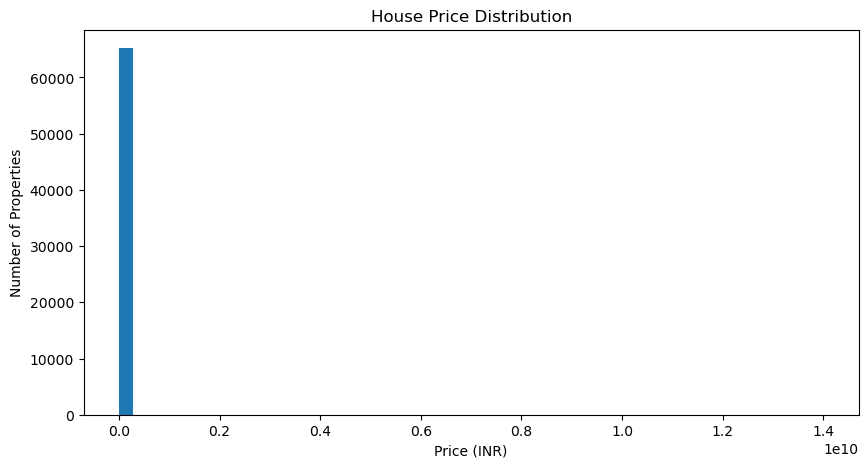

In [34]:
# 1: Visualize house price distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(houses["Amount_clean"].dropna(), bins=50)

plt.title("House Price Distribution")
plt.xlabel("Price (INR)")
plt.ylabel("Number of Properties")
plt.show()

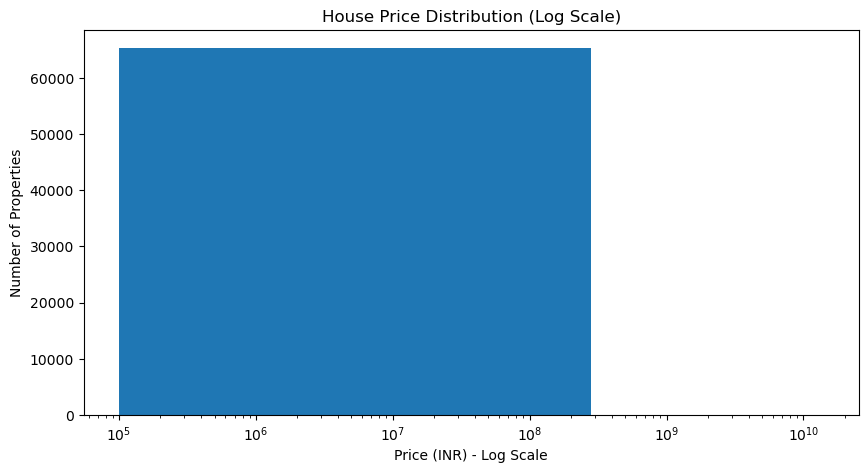

In [35]:
# Step 2: Visualize house prices using a logarithmic scale

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(houses["Amount_clean"].dropna(), bins=50)

plt.xscale("log")

plt.title("House Price Distribution (Log Scale)")
plt.xlabel("Price (INR) - Log Scale")
plt.ylabel("Number of Properties")

plt.show()

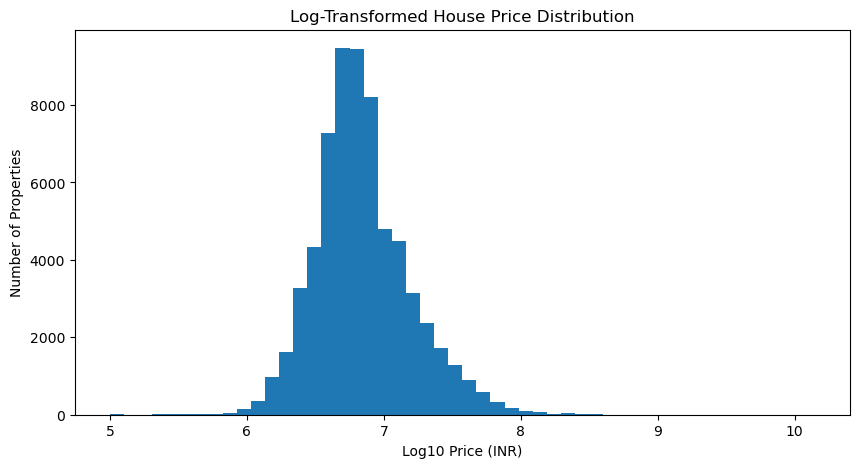

In [36]:
# Step 3: Visualize log-transformed house prices

import numpy as np

# Apply log10 to positive prices
prices = houses["Amount_clean"].dropna()
log_prices = np.log10(prices[prices > 0])

# Plot the distribution
plt.figure(figsize=(10, 5))
plt.hist(log_prices, bins=50)

plt.title("Log-Transformed House Price Distribution")
plt.xlabel("Log10 Price (INR)")
plt.ylabel("Number of Properties")

plt.show()

In [37]:
# 4: Detect price outliers using IQR
Q1 = houses["Amount_clean"].quantile(0.25)
Q3 = houses["Amount_clean"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Find potential outliers
outliers = (
    (houses["Amount_clean"] < lower) |
    (houses["Amount_clean"] > upper)
)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Outliers:", outliers.sum())

Q1: 4100000.0
Q3: 10900000.0
IQR: 6800000.0
Lower bound: -6100000.0
Upper bound: 21100000.0
Outliers: 6110


In [38]:
# 5: Inspect the highest-priced outlier properties

price_outliers = houses.loc[outliers]

price_outliers[[
    "Title",
    "Amount(in rupees)",
    "Amount_clean",
    "Area_sqft",
    "Area_Type",
    "location"
]].sort_values("Amount_clean", ascending=False).head(10)

,Title,Amount(in rupees),Amount_clean,Area_sqft,Area_Type,location
61898,3 BHK Ready to Occupy Flat for sale in Nest Ha...,1400.30 Cr,1.400300e+10,1252.0,Carpet,vadodara
57210,3 BHK Ready to Occupy Flat for sale Hill Cart ...,510.04 Cr,5.100400e+09,970.0,Carpet,siliguri
55568,2 BHK Ready to Occupy Flat for sale Kachna Road,396.75 Cr,3.967500e+09,920.0,Carpet,raipur
55687,2 BHK Ready to Occupy Flat for sale in Chaitan...,229.80 Cr,2.298000e+09,750.0,Carpet,raipur
63965,Studio Apartment for sale Awleshpur chitaipur...,80 Cr,8.000000e+08,20000.0,Super,varanasi
13673,5 BHK Ready to Occupy Flat for sale in DLF The...,60 Cr,6.000000e+08,11000.0,Super,gurgaon
13765,4 BHK Ready to Occupy Flat for sale in DLF Cam...,55 Cr,5.500000e+08,5400.0,Carpet,gurgaon
12029,5 BHK Ready to Occupy Flat for sale in DLF The...,55 Cr,5.500000e+08,5500.0,Carpet,gurgaon
14094,5 BHK Ready to Occupy Flat for sale in DLF Cam...,52 Cr,5.200000e+08,5250.0,Carpet,gurgaon
13672,5 BHK Ready to Occupy Flat for sale Golf Cours...,50 Cr,5.000000e+08,11000.0,Super,gurgaon


Total prices: 65255
Outliers: 6110
Outlier percentage: 9.36 %


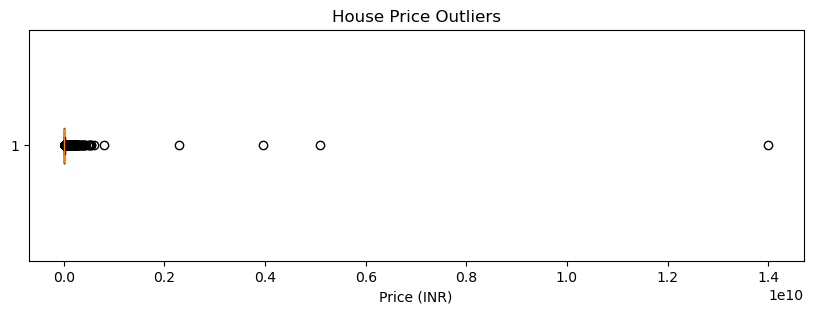

In [39]:
# Visualize and count price outliers

prices = houses["Amount_clean"].dropna()

# Count outliers
outliers = (prices < lower) | (prices > upper)

print("Total prices:", len(prices))
print("Outliers:", outliers.sum())
print("Outlier percentage:", round(outliers.mean() * 100, 2), "%")

# Draw boxplot
plt.figure(figsize=(10, 3))
plt.boxplot(prices, vert=False)
plt.title("House Price Outliers")
plt.xlabel("Price (INR)")
plt.show()

In [40]:
# Remove four price outliers

suspicious = [61898, 57210, 55568, 55687]
# Save suspicious records for review
suspicious_rows = houses.loc[suspicious].copy()

# Remove them from the dataset
houses = houses.drop(index=suspicious)

# Verify the result
print("Remaining rows:", len(houses))
print("Removed rows:", len(suspicious_rows))
print("Max price:", houses["Amount_clean"].max())

Remaining rows: 68188
Removed rows: 4
Max price: 800000000.0


Total prices: 65251
Outliers: 6106
Outlier percentage: 9.36 %


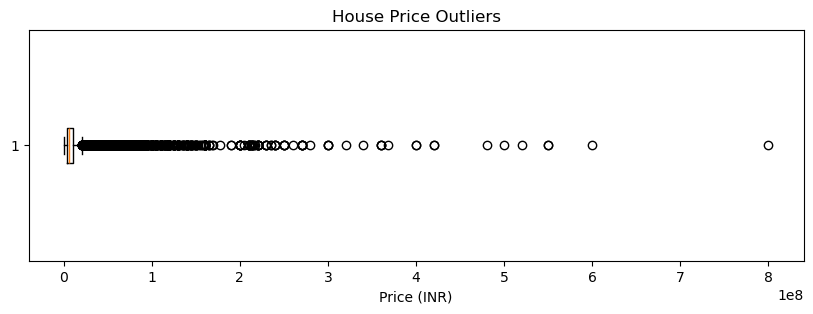

In [41]:
# Visualize and count price outliers

prices = houses["Amount_clean"].dropna()

# Count outliers
outliers = (prices < lower) | (prices > upper)

print("Total prices:", len(prices))
print("Outliers:", outliers.sum())
print("Outlier percentage:", round(outliers.mean() * 100, 2), "%")

# Draw boxplot
plt.figure(figsize=(10, 3))
plt.boxplot(prices, vert=False)
plt.title("House Price Outliers")
plt.xlabel("Price (INR)")
plt.show()

### Outlier Detection — Area_sqft (Property Area)

In [42]:
houses["Area_sqft"].describe()

count     68034.000000
mean       1354.224692
std        3822.558768
min           1.000000
25%         850.000000
50%        1150.000000
75%        1550.000000
max      709222.000000
Name: Area_sqft, dtype: float64

In [79]:
# Detect area outliers using IQR

Q1_area = houses["Area_sqft"].quantile(0.25)
Q3_area = houses["Area_sqft"].quantile(0.75)

IQR_area = Q3_area - Q1_area
print(Q1_area)
print(IQR_area)
print(IQR_area*1.5)

lower_area = Q1_area - 1.5 * IQR_area
upper_area = Q3_area + 1.5 * IQR_area

area_outliers = (
    (houses["Area_sqft"] < lower_area) |
    (houses["Area_sqft"] > upper_area)
)

print("Lower bound:", lower_area)
print("Upper bound:", upper_area)
print("Area outliers:", area_outliers.sum())

850.0
700.0
1050.0
Lower bound: -200.0
Upper bound: 2600.0
Area outliers: 3356


In [44]:
# Inspect the highest area outliers

area_outlier_rows = houses.loc[area_outliers]

area_outlier_rows[[
    "Title",
    "Area_sqft",
    "Area_Type",
    "Carpet Area",
    "Super Area",
    "location"
]].sort_values("Area_sqft", ascending=False).head(10)

,Title,Area_sqft,Area_Type,Carpet Area,Super Area,location
46768,2 BHK Ready to Occupy Flat for sale Kahilipara,709222.0,Carpet,709222 sqft,NaN,guwahati
32825,2 BHK Ready to Occupy Flat for sale Tapukara,495970.0,Carpet,495970 sqft,NaN,bhiwadi
31166,3 BHK Ready to Occupy Flat for sale Fatehabad ...,282004.0,Carpet,282004 sqft,NaN,agra
12603,3 BHK Ready to Occupy Flat for sale in TARC Ma...,194936.0,Carpet,194936 sqft,NaN,gurgaon
31377,3 BHK Ready to Occupy Flat for sale in Aparna ...,113134.0,Carpet,113134 sqft,NaN,agra
18197,3 BHK Ready to Occupy Flat for sale in Seven H...,107806.0,Carpet,107806 sqft,NaN,jaipur
60736,2 BHK Ready to Occupy Flat for sale Velappaya,81845.0,Carpet,81845 sqft,NaN,thrissur
57363,3 BHK Ready to Occupy Flat for sale Sevoke Road,81675.0,Carpet,81675 sqft,NaN,siliguri
37296,2 BHK Ready to Occupy Flat for sale yamnotri e...,72009.0,Carpet,8001 sqyrd,NaN,dehradun
57364,2 BHK Ready to Occupy Flat for sale Sevoke Road,71775.0,Carpet,71775 sqft,NaN,siliguri


In [45]:
# Inspect the highest area outliers

area_outlier_rows = houses.loc[area_outliers]

area_outlier_rows[[
    "Title",
    "Area_sqft",
    "Area_Type",
    "Carpet Area",
    "Super Area",
    "location"
]].sort_values("Area_sqft", ascending=True).head(10)

,Title,Area_sqft,Area_Type,Carpet Area,Super Area,location
9333,4 BHK Ready to Occupy Flat for sale in Lifesty...,2601.0,Super,NaN,2601 sqft,chennai
8786,4 BHK Ready to Occupy Flat for sale T Nagar,2601.0,Super,NaN,2601 sqft,chennai
9969,3 BHK Ready to Occupy Flat for sale in Lifesty...,2601.0,Super,NaN,2601 sqft,chennai
60163,3 BHK Ready to Occupy Flat for sale in Pramukh...,2602.0,Super,NaN,2602 sqft,surat
11816,3 BHK Ready to Occupy Flat for sale in Unitech...,2605.0,Super,NaN,2605 sqft,gurgaon
38599,4 BHK Ready to Occupy Flat for sale in Omaxe T...,2606.0,Carpet,2606 sqft,NaN,faridabad
12349,4 BHK Ready to Occupy Flat for sale in DLF The...,2606.0,Super,NaN,2606 sqft,gurgaon
38059,4 BHK Ready to Occupy Flat for sale in Omaxe T...,2606.0,Super,NaN,2606 sqft,faridabad
13166,3 BHK Ready to Occupy Flat for sale in M3M Gol...,2607.0,Carpet,2607 sqft,NaN,gurgaon
36802,4 BHK Ready to Occupy Flat for sale Mussoorie ...,2607.0,Super,NaN,2607 sqft,dehradun


Total areas: 68034
Outliers: 3362
Outlier percentage: 4.94 %


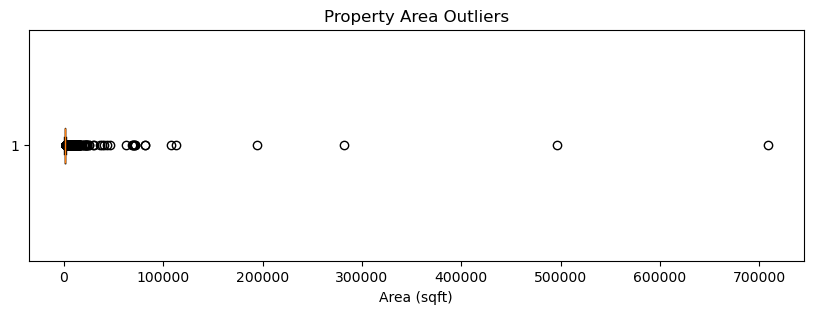

In [46]:
#  Visualize area outliers

areas = houses["Area_sqft"].dropna()

print("Total areas:", len(areas))
print("Outliers:", area_outliers.sum())
print("Outlier percentage:", round(area_outliers.sum() / len(areas) * 100, 2), "%")

plt.figure(figsize=(10, 3))
plt.boxplot(areas, vert=False)
plt.title("Property Area Outliers")
plt.xlabel("Area (sqft)")
plt.show()

In [75]:
# Remove five suspicious area outliers

suspicious_area = [46768, 32825, 31166, 12603, 31377, 18197]

suspicious_area_rows = houses.loc[suspicious_area].copy()

houses = houses.drop(index=suspicious_area)

print("Remaining rows:", len(houses))
print("Removed rows:", len(suspicious_area_rows))
print("Max area:", houses["Area_sqft"].max())

Remaining rows: 68186
Removed rows: 6
Max area: 81845.0


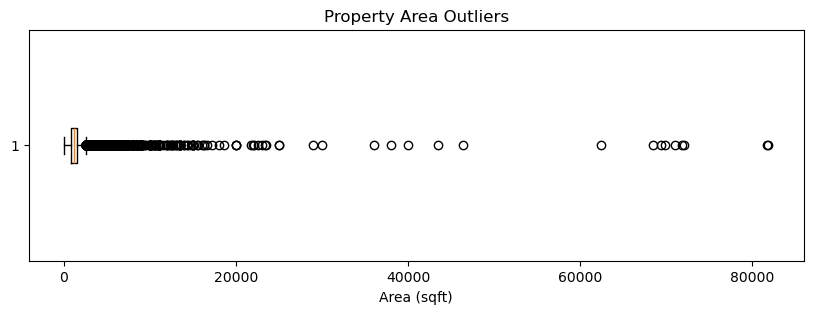

In [76]:
#  Visualize area outliers

areas = houses["Area_sqft"].dropna()

plt.figure(figsize=(10, 3))
plt.boxplot(areas, vert=False)
plt.title("Property Area Outliers")
plt.xlabel("Area (sqft)")
plt.show()

In [77]:
# Check properties with very small areas

small_areas = houses[houses["Area_sqft"] < 100]

print("Small areas:", len(small_areas))

small_areas[[
    "Title",
    "Area_sqft",
    "Carpet Area",
    "Super Area"
]].sort_values("Area_sqft", ascending=True).head(10)

Small areas: 130


,Title,Area_sqft,Carpet Area,Super Area
61343,2 BHK Ready to Occupy Flat for sale Fatehpura,1.0,NaN,1 sqft
57641,2 BHK Ready to Occupy Flat for sale in The New...,1.0,1 sqft,NaN
53104,2 BHK Ready to Occupy Flat for sale in Yesh Fa...,1.0,1 sqft,NaN
31313,3 BHK Ready to Occupy Flat for sale in Saptris...,1.0,1 sqft,NaN
66498,3 BHK Ready to Occupy Flat for sale Madhurawada,1.0,1 sqft,NaN
31744,3 BHK Ready to Occupy Flat for sale George Town,2.0,2 sqft,NaN
50860,3 BHK Ready to Occupy Flat for sale in Inland ...,5.0,5 sqft,NaN
64152,2 BHK Ready to Occupy Flat for sale orderly ba...,12.0,12 sqft,NaN
61145,3 BHK Ready to Occupy Flat for sale Sreekaryam,12.0,NaN,12 sqft
34623,4 BHK Ready to Occupy Flat for sale in Exotic ...,17.0,17 sqft,NaN


In [80]:
# Remove properties with unrealistic small areas

small_areas = houses[houses["Area_sqft"] < 100]
houses = houses[houses["Area_sqft"].isna() | (houses["Area_sqft"] >= 100)].copy()

print("Removed rows:", len(small_areas))
print("Remaining rows:", len(houses))
print("Minimum area:", houses["Area_sqft"].min())

houses[[
    "Title",
    "Area_sqft",
    "Carpet Area",
    "Super Area"
]].sort_values("Area_sqft", ascending=True).head(10)

Removed rows: 130
Remaining rows: 68056
Minimum area: 100.0


,Title,Area_sqft,Carpet Area,Super Area
17247,2 BHK Ready to Occupy Flat for sale in Padmasr...,100.0,100 sqft,NaN
48143,2 BHK Ready to Occupy Flat for sale in City Ho...,100.0,100 sqft,NaN
42788,2 BHK Ready to Occupy Flat for sale Dona Paula,100.0,NaN,100 sqft
26113,2 BHK Ready to Occupy Flat for sale Qutab Inst...,100.0,100 sqft,NaN
5186,2 BHK Ready to Occupy Flat for sale Ilaj compl...,100.0,100 sqft,NaN
53132,2 BHK Ready to Occupy Flat for sale Vijayanaga...,100.0,100 sqft,NaN
18909,2 BHK Ready to Occupy Flat for sale in Akshat ...,100.0,100 sqft,NaN
24978,3 BHK Ready to Occupy Flat for sale Partap Nag...,100.0,100 sqft,NaN
65324,2 BHK Ready to Occupy Flat for sale Pothinamal...,100.0,100 sqft,NaN
8687,1 BHK Ready to Occupy Flat for sale Old Mahaba...,100.0,100 sqft,NaN


### Outlier Detection — Bathroom

In [51]:
# Examine bathroom values and statistics

print(houses["Bathroom"].value_counts(dropna=False).sort_index())

Bathroom
1        6904
10         12
2       34624
3       19520
4        4921
5        1318
6         198
7          31
8          12
9           9
> 10       33
NaN       471
Name: count, dtype: int64


In [52]:
# Convert bathroom counts to numeric values

houses["Bathroom_clean"] = houses["Bathroom"].replace("> 10", 11)

houses["Bathroom_clean"] = pd.to_numeric(
    houses["Bathroom_clean"], errors="coerce"
)

print(houses["Bathroom_clean"].value_counts(dropna=False).sort_index())

Bathroom_clean
1.0      6904
2.0     34624
3.0     19520
4.0      4921
5.0      1318
6.0       198
7.0        31
8.0        12
9.0         9
10.0       12
11.0       33
NaN       471
Name: count, dtype: int64


## Outlier Detection — Balcony

In [53]:
# Examine balcony values and frequencies

print(houses["Balcony"].value_counts(dropna=False))

Balcony
NaN     19014
2       17745
1       15336
3        9617
4        3218
2.0       991
5         717
3.0       546
1.0       464
4.0       203
6         119
5.0        19
> 10       18
7          13
8          13
10         11
6.0         7
9           1
9.0         1
Name: count, dtype: int64


In [54]:
# Convert balcony counts to numeric values

houses["Balcony_clean"] = houses["Balcony"].replace("> 10", 11)

houses["Balcony_clean"] = pd.to_numeric(
    houses["Balcony_clean"], errors="coerce"
)

print(houses["Balcony_clean"].value_counts(dropna=False).sort_index())

Balcony_clean
1.0     15800
2.0     18736
3.0     10163
4.0      3421
5.0       736
6.0       126
7.0        13
8.0        13
9.0         2
10.0       11
11.0       18
NaN     19014
Name: count, dtype: int64


## Save the current DataFrame to S3 after outlier handling


In [55]:
import boto3
import io

s3 = boto3.client("s3")

bucket = "dataset-mlops"
key = "dataset/house prices/house_prices_cleaned_v2.csv"

houses.to_csv("houses.csv", index=False)

s3.upload_file(
    "houses.csv",
    "dataset-mlops",
    "dataset/house prices/house_prices_cleaned_v2.csv"
)

print("Saved to:", f"s3://{bucket}/{key}")
print("Rows:", len(houses))
print("Columns:", len(houses.columns))

Saved to: s3://dataset-mlops/dataset/house prices/house_prices_cleaned_v2.csv
Rows: 68053
Columns: 31


## Handling Missing Data

In [59]:
# Load the cleaned dataset from S3
response = s3.get_object(
    Bucket=bucket,
    Key=key
)

houses = pd.read_csv(response["Body"])

print("Loaded successfully!")
print("Shape:", houses.shape)
print("Rows:", len(houses))
print("Columns:", len(houses.columns))

Loaded successfully!
Shape: (68053, 31)
Rows: 68053
Columns: 31


/tmp/ipykernel_7140/1575822564.py:8: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  houses = pd.read_csv(response["Body"])


In [56]:
# Count missing values in each column

missing = houses.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

Car Parking       39209
Society           38727
Super_sqft        38124
Super Area        38104
Super_Unit        38104
Super_Value       38104
Carpet_sqft       30083
Carpet Area       30073
Carpet_Value      30073
Carpet_Unit       30073
overlooking       29443
facing            26717
Ownership         24851
Balcony           19014
Balcony_clean     19014
Amount_clean       2914
Amount_Value       2914
Floor              2615
Description        2214
Furnishing         1286
Bathroom            471
Bathroom_clean      471
Status              298
Area_sqft           154
Transaction          78
dtype: int64

### Handling Missing Values — Area_sqft 

In [60]:
# Inspect rows with missing property area

houses.loc[
    houses["Area_sqft"].isna(),
    ["Title", "Carpet Area", "Super Area", "Area_Type"]
].head(10)

,Title,Carpet Area,Super Area,Area_Type
71,1 BHK Ready to Occupy Flat for sale in Sagar R...,NaN,NaN,Unknown
1576,3 BHK Ready to Occupy Flat for sale Somalwada,NaN,NaN,Unknown
3912,2 BHK Ready to Occupy Flat for sale in Shukan ...,NaN,NaN,Unknown
5211,2 BHK Ready to Occupy Flat for sale in Ratnaak...,NaN,NaN,Unknown
5552,1 BHK Ready to Occupy Flat for sale Krishna Na...,NaN,NaN,Unknown
5638,3 BHK Ready to Occupy Flat for sale Visl Layou...,NaN,1810 marla,Unknown
7665,Apartment for sale in Krishna Residency Horamavu,NaN,NaN,Unknown
7787,1 BHK Ready to Occupy Flat for sale in Concord...,NaN,NaN,Unknown
7788,1 BHK Ready to Occupy Flat for sale in Concord...,NaN,NaN,Unknown
8582,2 BHK Ready to Occupy Flat for sale Kalena Agr...,NaN,NaN,Unknown


In [61]:
# Find missing areas with available original area values

recoverable = houses[
    houses["Area_sqft"].isna()
    & (
        houses["Carpet Area"].notna()
        | houses["Super Area"].notna()
    )
]

print("Missing areas:", houses["Area_sqft"].isna().sum())
print("Potentially recoverable:", len(recoverable))

recoverable[[
    "Title",
    "Carpet Area",
    "Super Area",
    "Area_Type"
]].head(10)

Missing areas: 154
Potentially recoverable: 30


,Title,Carpet Area,Super Area,Area_Type
5638,3 BHK Ready to Occupy Flat for sale Visl Layou...,NaN,1810 marla,Unknown
23431,3 BHK Ready to Occupy Flat for sale in The Nes...,1500 acre,NaN,Unknown
24194,6 BHK Ready to Occupy Flat for sale in LDA PAR...,2 acre,NaN,Unknown
31444,5 BHK Ready to Occupy Flat for sale Dayal Bagh,3 ground,NaN,Unknown
34351,3 BHK Ready to Occupy Flat for sale Sector 38 ...,NaN,8 marla,Unknown
34416,"2 BHK Ready to Occupy Flat for sale Sector 19,...",NaN,4 marla,Unknown
34451,2 BHK Ready to Occupy Flat for sale Sector 22B,NaN,5 marla,Unknown
34547,5 BHK Ready to Occupy Flat for sale in AWHO Na...,NaN,4 kanal,Unknown
34575,2 BHK Ready to Occupy Flat for sale Sector 38A,NaN,8 marla,Unknown
34870,9 BHK Ready to Occupy Flat for sale Sector-38,NaN,8 marla,Unknown


In [62]:
# Fill missing values in Area_sqft using the median

area_median = houses["Area_sqft"].median()

houses["Area_sqft"] = houses["Area_sqft"].fillna(area_median)

print("Median area:", area_median)
print("Missing areas after filling:", houses["Area_sqft"].isna().sum())

Median area: 1150.0
Missing areas after filling: 0


In [64]:
# Verify missing values and area statistics

print("Missing values:", houses["Area_sqft"].isna().sum())

Missing values: 0


### Handling Missing Values — Bathroom_clean

In [65]:
print(houses["Bathroom_clean"].value_counts(dropna=False).sort_index())

Bathroom_clean
1.0      6904
2.0     34624
3.0     19520
4.0      4921
5.0      1318
6.0       198
7.0        31
8.0        12
9.0         9
10.0       12
11.0       33
NaN       471
Name: count, dtype: int64


In [66]:
#  Calculate the median number of bathrooms

bathroom_median = houses["Bathroom_clean"].median()

print("Bathroom median:", bathroom_median)

Bathroom median: 2.0


In [67]:
# Fill missing bathroom values using the median

houses["Bathroom_clean"] = houses["Bathroom_clean"].fillna(
    bathroom_median
)

print("Missing values after filling:",
      houses["Bathroom_clean"].isna().sum())

Missing values after filling: 0


### Handling Missing Values — Balcony_clean

In [68]:
# Calculate the median number of balconies

balcony_median = houses["Balcony_clean"].median()

print("Balcony median:", balcony_median)

Balcony median: 2.0


In [71]:
#  Fill missing balcony values using the median

houses["Balcony_clean"] = houses["Balcony_clean"].fillna(
    balcony_median
)

print("Missing values after filling:",
      houses["Balcony_clean"].isna().sum())

Missing values after filling: 0


### Handling Missing Values — Car Parking

In [73]:
# Check Car Parking values and missing values

print(houses["Car Parking"].value_counts(dropna=False).head(15))

Car Parking
NaN           39209
1 Covered     15772
1 Covered,     4099
1 Open         3439
2 Covered      2979
2 Covered,      875
3 Covered       380
2 Open          372
3 Covered,      111
4 Covered       100
3 Open           37
5 Covered        32
4 Covered,       27
10 Open          26
4 Open           25
Name: count, dtype: int64


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset from local PC
df = pd.read_csv("House Prices.csv")

# Create a working copy
houses = df.copy()

print("Dataset shape:", houses.shape)
display(houses.head())

Dataset shape: (21613, 21)


,ID,Date,Price,Bedrooms,Bathrooms,Sqft_living,Sqft_lot,Floors,Waterfront,View,...,Grade,Sqft_above,Sqft_basement,Yr_built,Yr_renovated,zipcode,Lat,Long,Sqft_living15,Sqft_lot15
0,1,20140916T000000,280000.0,6,3.00,2400,9373,2.0,0,0,...,7,2400,0,1991,0,98002,47.3262,-122.214,2060,7316
1,2,20150422T000000,300000.0,6,3.00,2400,9373,2.0,0,0,...,7,2400,0,1991,0,98002,47.3262,-122.214,2060,7316
2,3,20140508T000000,647500.0,4,1.75,2060,26036,1.0,0,0,...,8,1160,900,1947,0,98166,47.4444,-122.351,2590,21891
3,4,20140811T000000,400000.0,3,1.00,1460,43000,1.0,0,0,...,7,1460,0,1952,0,98166,47.4434,-122.347,2250,20023
4,5,20150401T000000,235000.0,3,1.00,1430,7599,1.5,0,0,...,6,1010,420,1930,0,98168,47.4783,-122.265,1290,10320


In [36]:
print(houses.info())
display(houses.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             21613 non-null  int64  
 1   Date           21613 non-null  object 
 2   Price          21613 non-null  float64
 3   Bedrooms       21613 non-null  int64  
 4   Bathrooms      21613 non-null  float64
 5   Sqft_living    21613 non-null  int64  
 6   Sqft_lot       21613 non-null  int64  
 7   Floors         21613 non-null  float64
 8   Waterfront     21613 non-null  int64  
 9   View           21613 non-null  int64  
 10  Condition      21613 non-null  int64  
 11  Grade          21613 non-null  int64  
 12  Sqft_above     21613 non-null  int64  
 13  Sqft_basement  21613 non-null  int64  
 14  Yr_built       21613 non-null  int64  
 15  Yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  Lat            21613 non-null  float64
 18  Long  

,count,mean,std,min,25%,50%,75%,max
ID,21613.0,10807.000000,6239.280020,1.0000,5404.000,10807.0000,16210.000,2.161300e+04
Price,21613.0,540182.158793,367362.231718,75000.0000,321950.000,450000.0000,645000.000,7.700000e+06
Bedrooms,21613.0,3.370842,0.930062,0.0000,3.000,3.0000,4.000,3.300000e+01
Bathrooms,21613.0,2.114757,0.770163,0.0000,1.750,2.2500,2.500,8.000000e+00
Sqft_living,21613.0,2079.899736,918.440897,290.0000,1427.000,1910.0000,2550.000,1.354000e+04
Sqft_lot,21613.0,15106.967566,41420.511515,520.0000,5040.000,7618.0000,10688.000,1.651359e+06
Floors,21613.0,1.494309,0.539989,1.0000,1.000,1.5000,2.000,3.500000e+00
Waterfront,21613.0,0.007542,0.086517,0.0000,0.000,0.0000,0.000,1.000000e+00
View,21613.0,0.234303,0.766318,0.0000,0.000,0.0000,0.000,4.000000e+00
Condition,21613.0,3.409430,0.650743,1.0000,3.000,3.0000,4.000,5.000000e+00


In [37]:
quality_report = pd.DataFrame({
    "dtype": houses.dtypes.astype(str),
    "missing_count": houses.isna().sum(),
    "missing_percent": (houses.isna().mean() * 100).round(2),
    "unique_values": houses.nunique()
})
display(quality_report)


,dtype,missing_count,missing_percent,unique_values
ID,int64,0,0.0,21613
Date,object,0,0.0,372
Price,float64,0,0.0,3625
Bedrooms,int64,0,0.0,13
Bathrooms,float64,0,0.0,30
Sqft_living,int64,0,0.0,1038
Sqft_lot,int64,0,0.0,9782
Floors,float64,0,0.0,6
Waterfront,int64,0,0.0,2
View,int64,0,0.0,5


In [38]:
print("Exact duplicate rows:", houses.duplicated().sum())
print("Duplicate IDs:", houses["ID"].duplicated().sum())

houses = houses.drop_duplicates().copy()

Exact duplicate rows: 0
Duplicate IDs: 0


In [39]:
# Fix dates
houses["Date"] = pd.to_datetime(
    houses["Date"].astype(str).str.replace(r"\.0$", "", regex=True),
    format="%Y%m%dT%H%M%S",
    errors="coerce"
)
# Convert numeric columns
numeric_cols = houses.columns.drop("Date")
for col in numeric_cols:
    houses[col] = pd.to_numeric(houses[col], errors="coerce")

print("Invalid dates:", houses["Date"].isna().sum())
print(houses.dtypes)


Invalid dates: 0
ID                        int64
Date             datetime64[ns]
Price                   float64
Bedrooms                  int64
Bathrooms               float64
Sqft_living               int64
Sqft_lot                  int64
Floors                  float64
Waterfront                int64
View                      int64
Condition                 int64
Grade                     int64
Sqft_above                int64
Sqft_basement             int64
Yr_built                  int64
Yr_renovated              int64
zipcode                   int64
Lat                     float64
Long                    float64
Sqft_living15             int64
Sqft_lot15                int64
dtype: object


In [40]:
checks = {
    "non_positive_price": houses["Price"] <= 0,
    "non_positive_living_area": houses["Sqft_living"] <= 0,
    "negative_lot_area": houses["Sqft_lot"] < 0,
    "bedrooms_over_15": houses["Bedrooms"] > 15,
    "bathrooms_over_10": houses["Bathrooms"] > 10,
    "invalid_waterfront": ~houses["Waterfront"].isin([0, 1]),
    "invalid_view": ~houses["View"].between(0, 4),
    "invalid_condition": ~houses["Condition"].between(1, 5),
    "invalid_grade": ~houses["Grade"].between(1, 13),
    "invalid_latitude": ~houses["Lat"].between(-90, 90),
    "invalid_longitude": ~houses["Long"].between(-180, 180),
}
for name, mask in checks.items():
    print(f"{name}: {int(mask.fillna(False).sum())}")

display(houses.loc[houses["Bedrooms"] > 15,
                   ["ID", "Price", "Bedrooms", "Bathrooms", "Sqft_living", "Sqft_lot"]])


non_positive_price: 0
non_positive_living_area: 0
negative_lot_area: 0
bedrooms_over_15: 1
bathrooms_over_10: 0
invalid_waterfront: 0
invalid_view: 0
invalid_condition: 0
invalid_grade: 0
invalid_latitude: 0
invalid_longitude: 0


,ID,Price,Bedrooms,Bathrooms,Sqft_living,Sqft_lot
6075,6076,640000.0,33,1.75,1620,6000


In [41]:
missing_before = houses.isna().sum().sort_values(ascending=False)
display(missing_before[missing_before > 0])

Series([], dtype: int64)

In [43]:
# Select numerical columns for outlier detection
outlier_cols = [
    'Price',
    'Sqft_living',
    'Sqft_lot',
    'Sqft_above',
    'Sqft_basement',
    'Sqft_living15',
    'Sqft_lot15'
]

Q1 = houses[outlier_cols].quantile(0.25)
Q3 = houses[outlier_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (houses[outlier_cols] < lower_bound) |
    (houses[outlier_cols] > upper_bound)
)

print("Outliers before removal:")
print(outliers.sum())

houses_cleaned = houses[~outliers.any(axis=1)].copy()

print("\nOriginal dataset shape:", houses.shape)
print("After removing outliers:", houses_cleaned.shape)
print("Removed rows:", len(houses) - len(houses_cleaned))

Outliers before removal:
Price            1159
Sqft_living       572
Sqft_lot         2425
Sqft_above        611
Sqft_basement     496
Sqft_living15     544
Sqft_lot15       2194
dtype: int64

Original dataset shape: (21613, 21)
After removing outliers: (17642, 21)
Removed rows: 3971
